# 実データ版 One-Device Latent Heteroscedastic Gaussian Process

このノートブックは、`one_device_latent_heteroscedastic_gp_full.ipynb` を実データ用に調整した1装置版です。

`0_Data/2_Compiled_Data` の XRF vs XRD/EPMA 比較データから、`DEVICE_TO_USE` で選んだ1装置の signed relative error [%] をモデル化します。

$$
e_i = 100 \times \frac{\mathrm{Measured}_i - \mathrm{XRF}_i}{\mathrm{XRF}_i}
$$

モデルは元ノートブックと同じ Latent heteroscedastic GP です。

$$
e_i \sim \mathcal{N}(f(x_i), \sigma_i^2), \qquad \log \sigma_i = h_0 + h_{\mathrm{raw}}(x_i)
$$


> Inference variant: `ADVI_tstudent`. This notebook uses variational inference instead of NUTS-MCMC. The observation likelihood is Student-t with fixed `STUDENT_T_NU`.


In [1]:
import time

start = time.perf_counter()


## 0. Imports

必要なライブラリを読み込みます。

In [2]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import pymc as pm
import arviz as az
import matplotlib.pyplot as plt

from IPython.display import display


/Users/satoshimatsuno/Library/Caches/pypoetry/virtualenvs/pxrd-validation-ms--qvz1pt9-py3.11/lib/python3.11/site-packages/arviz/__init__.py:50: FutureWarning: 
ArviZ is undergoing a major refactor to improve flexibility and extensibility while maintaining a user-friendly interface.
Some upcoming changes may be backward incompatible.
For details and migration guidance, visit: https://python.arviz.org/en/latest/user_guide/migration_guide.html
  warn(


## 1. Settings

`DEVICE_TO_USE` を変更すると、`SR-PXRD`, `LAB-PXRD`, `EPMA` のうち1装置を解析できます。

In [3]:
# ============================================================
# Global settings
# ============================================================

RANDOM_SEED = 123
rng = np.random.default_rng(RANDOM_SEED)

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "2_Program":
    PROJECT_ROOT = PROJECT_ROOT.parent
if PROJECT_ROOT.name == "0_6_one_device_latent_heteroscedastic_gp_real_data_ADVI":
    PROJECT_ROOT = PROJECT_ROOT.parent.parent

DATA_DIR = PROJECT_ROOT / "0_Data" / "2_Compiled_Data"

# ============================================================
# Real data settings
# ============================================================

INSTRUMENT_ORDER = ["SR-PXRD", "LAB-PXRD", "EPMA"]
INSTRUMENT_TARGET_COLUMNS = {
    "SR-PXRD": "XRD_SP8",
    "LAB-PXRD": "XRD_LAB",
    "EPMA": "EPMA",
}

# 解析する1装置を選ぶ: "SR-PXRD", "LAB-PXRD", or "EPMA"
# DEVICE_TO_USE = "LAB-PXRD"
# DEVICE_TO_USE = "EPMA"
DEVICE_TO_USE = "SR-PXRD"

# None の場合は全 oxide を使う。例: ["SiO2", "Al2O3", "Fe2O3"]
SELECTED_OXIDES = None

# ============================================================
# Input transform settings
# ============================================================

# 実データは濃度レンジが広いため、log10(ref_wt + LOG_OFFSET) を標準化してGPに入れる。
X_TRANSFORM = "log10"
LOG_OFFSET = 1e-6

# ============================================================
# GP kernel settings
# ============================================================

# "ExpQuad": RBF / squared exponential kernel
# "Matern52": Matérn 5/2 kernel
KERNEL_TYPE = "ExpQuad"
# KERNEL_TYPE = "Matern52"

# 共分散行列の数値安定化用 jitter
JITTER = 1e-6

# ============================================================
# MCMC settings
# ============================================================

DRAWS = 2000
TUNE = 3000

# DRAWS = 200
# TUNE = 200

CHAINS = 4
# Jupyter上でPyMCのmultiprocessingがEOFErrorになることがあるため、chainは逐次実行する。
CORES = 1 # run chains sequentially; parallel chains can raise EOFError in Jupyter
TARGET_ACCEPT = 0.995 # increase for difficult GP posteriors

# ============================================================
# GP prior settings
# ============================================================

# x is standardized after log10 transform. Larger beta/alpha here favors
# smoother concentration dependence in the log-sigma GP.
ELL_F_PRIOR_ALPHA = 3.0
ELL_F_PRIOR_BETA = 2.0
ELL_H_PRIOR_ALPHA = 6.0
ELL_H_PRIOR_BETA = 5.0
ETA_H_PRIOR_SIGMA = 0.7

# ============================================================
# Variational inference settings
# ============================================================

RESULT_SUFFIX = "ADVI_tstudent"
# Original setting:
# VI_METHOD = "fullrank_advi"  # "advi" or "fullrank_advi"

# Mean-field ADVI is more stable for this high-dimensional latent GP.
VI_METHOD = "advi"
VI_STEPS = 100_000
VI_SAMPLES = 4_000
VI_LEARNING_RATE = 1e-4
STUDENT_T_NU = 4.0

# ============================================================
# Prediction settings
# ============================================================

N_GRID = 100
PRED_SUFFIX = "real_v1"

# ============================================================
# Output settings
# ============================================================

# OUTPUT_DIR = PROJECT_ROOT / "2_Program" / "outputs" / "one_device_latent_hgp_real_data"
# FIGURE_DIR = OUTPUT_DIR / "figures"

OUTPUT_DIR = PROJECT_ROOT / "0_Data" / "3_Figure" / "Mineral_Mode_Relative_Error"
FIGURE_DIR = OUTPUT_DIR 

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print("PROJECT_ROOT:", PROJECT_ROOT)
print("DATA_DIR:", DATA_DIR)
print("OUTPUT_DIR:", OUTPUT_DIR)


PROJECT_ROOT: /Volumes/SSD-PHPU3A/研究/0_DATA/6_EPMA_XRD検証
DATA_DIR: /Volumes/SSD-PHPU3A/研究/0_DATA/6_EPMA_XRD検証/0_Data/2_Compiled_Data
OUTPUT_DIR: /Volumes/SSD-PHPU3A/研究/0_DATA/6_EPMA_XRD検証/0_Data/3_Figure/Mineral_Mode_Relative_Error


## 2. Real Data Compile

XRFを参照値として、選択した装置の signed relative error [%] を作成します。

In [4]:
def validate_device(device):
    if device not in INSTRUMENT_ORDER:
        raise ValueError(f"DEVICE_TO_USE must be one of {INSTRUMENT_ORDER}, got: {device}")
    return device


def load_real_device_error_data(data_dir, selected_oxides=None):
    """XRFを参照値として、装置ごとのsigned relative error [%]をlong formatで作る。"""
    xrd = pd.read_excel(
        data_dir / "df_volume_mineral_comp_>bulk_comp_melt.xlsx",
        index_col=0,
        header=0,
    ).rename(columns={"variable": "oxides"})

    epma = pd.read_excel(
        data_dir / "df_volume_mineral_comp_>bulk_comp_melt_EPMA.xlsx",
        index_col=0,
        header=0,
    ).rename(columns={"variable": "oxides"})

    rows = []
    for source_df, targets in [
        (xrd, {"SR-PXRD": "XRD_SP8", "LAB-PXRD": "XRD_LAB"}),
        (epma, {"EPMA": "EPMA"}),
    ]:
        for device, target_col in targets.items():
            use = source_df[["INDEX", "oxides", "XRF", target_col]].copy()
            use = use.rename(columns={"XRF": "ref_wt", target_col: "measured_wt"})
            use["device"] = device
            rows.append(use)

    data = pd.concat(rows, ignore_index=True)
    data = data.replace([np.inf, -np.inf], np.nan)
    data = data.dropna(subset=["device", "oxides", "ref_wt", "measured_wt"])

    excluded_non_positive = int((data["ref_wt"] <= 0).sum())
    data = data[data["ref_wt"] > 0].copy()

    if selected_oxides is not None:
        data = data[data["oxides"].astype(str).isin(selected_oxides)].copy()

    data["error"] = (data["measured_wt"] - data["ref_wt"]) / data["ref_wt"] * 100.0
    data["device"] = pd.Categorical(data["device"], categories=INSTRUMENT_ORDER, ordered=True)
    data["log_ref_wt"] = np.log10(data["ref_wt"])

    cols = ["device", "INDEX", "oxides", "ref_wt", "measured_wt", "error", "log_ref_wt"]
    data = data[cols].sort_values(["device", "INDEX", "oxides"]).reset_index(drop=True)

    return data, excluded_non_positive


validate_device(DEVICE_TO_USE)
all_data, excluded_non_positive = load_real_device_error_data(
    DATA_DIR,
    selected_oxides=SELECTED_OXIDES,
)

df = all_data[all_data["device"].astype(str) == DEVICE_TO_USE].copy()
if df.empty:
    raise ValueError(f"No rows found for DEVICE_TO_USE={DEVICE_TO_USE!r}.")

print(f"all_data: {all_data.shape}")
print(f"selected df: {df.shape}")
print(f"Excluded rows with ref_wt <= 0: {excluded_non_positive}")
print("device =", DEVICE_TO_USE)
print("ref_wt range =", (df["ref_wt"].min(), df["ref_wt"].max()))
print("error mean, sd =", (df["error"].mean(), df["error"].std()))
print("n oxides =", df["oxides"].nunique())

display(df.head())
display(df.groupby("oxides", observed=True).size().rename("n").sort_values(ascending=False))


all_data: (1040, 7)
selected df: (480, 7)
Excluded rows with ref_wt <= 0: 0
device = SR-PXRD
ref_wt range = (np.float64(0.064), np.float64(75.06))
error mean, sd = (np.float64(-3.3119204638974753), np.float64(22.73837035051454))
n oxides = 10


,device,INDEX,oxides,ref_wt,measured_wt,error,log_ref_wt
0,SR-PXRD,45,Al2O3,14.445,13.455476,-6.850286,1.159718
1,SR-PXRD,45,CaO,0.462,0.541821,17.277245,-0.335358
2,SR-PXRD,45,Fe2O3,4.032,2.945725,-26.941343,0.605521
3,SR-PXRD,45,K2O,2.872,2.564678,-10.700613,0.458184
4,SR-PXRD,45,MgO,1.663,1.386113,-16.649855,0.220892


oxides
Al2O3    48
CaO      48
Fe2O3    48
K2O      48
MgO      48
MnO      48
Na2O     48
P2O5     48
SiO2     48
TiO2     48
Name: n, dtype: int64

## 3. Observed Data

観測された signed relative error を確認します。

Saved: /Volumes/SSD-PHPU3A/研究/0_DATA/6_EPMA_XRD検証/0_Data/3_Figure/Mineral_Mode_Relative_Error/observed_error_SR-PXRD.png


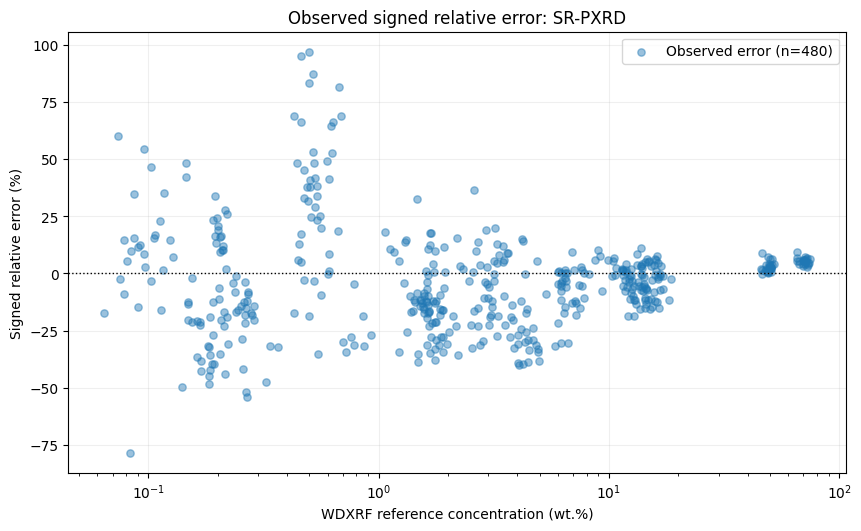

In [5]:
def safe_name(name):
    return str(name).replace("/", "-").replace(" ", "_")


def plot_observed_data(df, save_path=None):
    fig, ax = plt.subplots(figsize=(8.5, 5.2), constrained_layout=True)

    ax.scatter(
        df["ref_wt"],
        df["error"],
        alpha=0.45,
        s=28,
        label=f"Observed error (n={len(df)})",
    )

    ax.axhline(0, linestyle=":", linewidth=1, color="black")
    ax.set_xscale("log")
    ax.set_xlabel("WDXRF reference concentration (wt.%)")
    ax.set_ylabel("Signed relative error (%)")
    ax.set_title(f"Observed signed relative error: {DEVICE_TO_USE}")
    ax.grid(True, which="major", alpha=0.2)
    ax.legend()

    if save_path is not None:
        save_path = Path(save_path)
        save_path.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_path, dpi=300, bbox_inches="tight")
        print(f"Saved: {save_path}")

    plt.show()


plot_observed_data(
    df,
    save_path=FIGURE_DIR / f"observed_error_{safe_name(DEVICE_TO_USE)}.png",
)


## 5. 入力変換とカーネル関数

GPに入れる \(x\) は、以下のどちらかで変換します。

### standard

$$
\tilde{x} = \frac{x-\bar{x}}{s_x}
$$

### log10

$$
\tilde{x} = \mathrm{standardize}\{\log_{10}(x+c)\}
$$

低濃度側で急激に誤差や分散が変わる場合は `log10` を検討します。

カーネルは次のどちらかを選べます。

### ExpQuad

$$
k(x,x')=\eta^2\exp\left[-\frac{(x-x')^2}{2\ell^2}\right]
$$

非常に滑らかな関数を仮定します。

### Matérn 5/2

ExpQuadより少し粗い変化を許します。実験データではこちらの方が現実的な場合があります。

In [6]:
def transform_x_train(x_raw, transform="standard", log_offset=1e-3):
    """
    学習データのxを変換・標準化する。
    """
    x_raw = np.asarray(x_raw, dtype=float)

    if transform == "standard":
        x_base = x_raw

    elif transform == "log10":
        x_base = np.log10(x_raw + log_offset)

    else:
        raise ValueError("transform must be 'standard' or 'log10'.")

    x_mean = x_base.mean()
    x_std = x_base.std()

    if x_std == 0:
        raise ValueError("Transformed x has zero standard deviation.")

    x_scaled = (x_base - x_mean) / x_std

    transform_meta = {
        "transform": transform,
        "log_offset": log_offset,
        "x_mean": x_mean,
        "x_std": x_std,
    }

    return x_scaled, transform_meta


def transform_x_new(x_raw, transform_meta):
    """
    学習時と同じ変換で、新しいxを標準化する。
    """
    x_raw = np.asarray(x_raw, dtype=float)

    transform = transform_meta["transform"]
    log_offset = transform_meta["log_offset"]

    if transform == "standard":
        x_base = x_raw

    elif transform == "log10":
        x_base = np.log10(x_raw + log_offset)

    else:
        raise ValueError("Unknown transform.")

    return (x_base - transform_meta["x_mean"]) / transform_meta["x_std"]


def make_covariance(kernel_type, eta, ell, input_dim=1, jitter=1e-6):
    """
    GPの共分散関数を作る。

    WhiteNoiseは、測定ノイズを表しているのではなく、
    GP共分散行列のCholesky分解を安定化するための小さな対角成分。
    """
    if kernel_type == "ExpQuad":
        base = pm.gp.cov.ExpQuad(input_dim=input_dim, ls=ell)

    elif kernel_type == "Matern52":
        base = pm.gp.cov.Matern52(input_dim=input_dim, ls=ell)

    else:
        raise ValueError("kernel_type must be 'ExpQuad' or 'Matern52'.")

    return eta**2 * base + pm.gp.cov.WhiteNoise(sigma=jitter)


## 5. Model Definition

1装置版 Latent heteroscedastic GP を定義します。lengthscale prior と log-sigma GP の振幅 prior は設定セルで明示します。

LAB-PXRDでは分散GPのMCMC混合が悪かったため、log-sigma GPには短すぎるlengthscaleと過大な振幅を抑える弱情報事前分布を使います。

This variant uses `pm.fit(..., method=VI_METHOD)` and draws posterior samples from the variational approximation. MCMC diagnostics such as r_hat and divergences are not available for this inference method.

The original Normal likelihood is left commented in the model cell, and the active likelihood is Student-t.

### モデルの階層構造

$$
f(x)\sim\mathrm{GP}\!\left(0,k_f(x,x';\eta_f,\ell_f)\right)
$$

$$
h_{\mathrm{raw}}(x)\sim\mathrm{GP}\!\left(0,k_h(x,x';\eta_h,\ell_h)\right)
$$

$$
\log\sigma(x)=h_0+h_{\mathrm{raw}}(x),\qquad
\sigma(x)=\exp\!\left[\log\sigma(x)\right]
$$

$$
e_i\mid f(x_i),\sigma(x_i),\nu
\sim\mathrm{StudentT}\!\left(\nu,\mu=f(x_i),\mathrm{scale}=\sigma(x_i)\right)
$$

$f(x)$ は濃度に依存する潜在平均誤差、$\sigma(x)$ は濃度に依存する Student-t error scale です。$\nu>1$ では条件付き平均が $f(x)$ になり、$\nu>2$ では条件付き標準偏差が $\sigma(x)\sqrt{\nu/(\nu-2)}$ になります。このノートブックでは $\nu=4$ なので、条件付き標準偏差は $\sqrt{2}\,\sigma(x)$ です。

### 入力データと前処理に関する変数

| 変数 | 内容 |
|---|---|
| `df_device` | 対象装置の学習データです。濃度 `ref_wt` と signed relative error `error` を含みます。 |
| `x_raw` | `ref_wt` から取り出した未変換の WDXRF reference concentration（wt.%）です。 |
| `e` | 観測された signed relative error（%）です。Student-t 尤度の `observed` に渡されます。 |
| `x_scaled` | `log10(ref_wt + log_offset)` を学習データ内で標準化した値です。GP はこの尺度上で濃度依存性を学習します。 |
| `transform_meta` | 新しい濃度にも同じ変換を適用するための変換方法、offset、平均、標準偏差を保存します。 |
| `X` | PyMC の GP が要求する `(n_observations, 1)` 形状にした `x_scaled` です。 |
| `e_sd` | 観測誤差 `e` の代表的な大きさです。`eta_f` と `h0` の弱情報事前分布を設定する基準に使われ、尤度の標準偏差として直接使われるわけではありません。 |

### 平均誤差 GP に関する変数

| 変数 | 内容 |
|---|---|
| `ell_f` | 平均関数 $f(x)$ の lengthscale $\ell_f$ です。小さいほど濃度に対して細かく変化し、大きいほど滑らかに変化します。入力が標準化されているため、その尺度上の値です。 |
| `eta_f` | $f(x)$ の縦方向の振幅 $\eta_f$ です。平均誤差曲線が0付近からどの程度変動し得るかを制御します。観測誤差の標準偏差ではありません。 |
| `cov_f` | `ell_f` と `eta_f` から作る平均GPの共分散関数です。`KERNEL_TYPE` に従って ExpQuad または Matérn 5/2 を使用します。 |
| `gp_f` | `cov_f` を持つ潜在平均GPオブジェクトです。 |
| `f` | 各学習濃度 $x_i$ における潜在平均誤差 $f(x_i)$ です。Student-t 尤度の位置パラメータ `mu` に渡されます。単位は percent です。 |

### Error scale GP に関する変数

| 変数 | 内容 |
|---|---|
| `ell_h` | log-scale 関数の lengthscale $\ell_h$ です。error scale が濃度に対して変化する速さを制御し、`ell_f` とは別に推定されます。 |
| `eta_h` | $h_{\mathrm{raw}}(x)$ の振幅 $\eta_h$ です。濃度による log-scale の変動幅を制御します。log-scale 上の量なので無次元です。 |
| `cov_h` | `ell_h` と `eta_h` から作る log-scale GP の共分散関数です。 |
| `gp_h` | `cov_h` を持つ潜在 log-scale GP オブジェクトです。 |
| `h0` | $\log\sigma(x)$ の全体的な基準値です。事前分布の中心には $\log(e_{\mathrm{sd}})$ を使います。 |
| `h_raw` | 各学習濃度での平均0の潜在GP成分 $h_{\mathrm{raw}}(x_i)$ です。濃度に依存する相対的な log-scale の変化を表します。 |
| `log_sigma` | $h_0+h_{\mathrm{raw}}(x_i)$ で定義される $\log\sigma(x_i)$ です。実装上の名前は `log_sigma` ですが、Student-t 尤度では log standard deviation ではなく log scale を意味します。 |
| `sigma` | $\exp(\mathrm{log\_sigma})$ で正値に変換した Student-t error scale $\sigma(x_i)$ です。尤度の `sigma` に渡され、単位は percent です。標準偏差そのものではありません。 |

`cov_f` と `cov_h` に加える `jitter`（WhiteNoise）は、GP共分散行列の数値計算を安定化するための微小な対角成分です。観測誤差や追加の測定ノイズを表すパラメータではありません。

### 尤度と推論に関する変数

| 変数 | 内容 |
|---|---|
| `student_t_nu` | Student-t 分布の自由度 $\nu$ です。小さいほど裾が重く、極端な誤差の影響を弱めます。このノートブックでは4に固定します。 |
| `error_obs` | `mu=f`、`sigma=sigma`、`nu=student_t_nu` と観測値 `e` を結ぶ Student-t 尤度です。 |
| `approx` | `pm.fit` によって最適化された変分事後近似です。 |
| `idata` | `approx` から抽出した事後標本を格納する ArviZ `InferenceData` です。第8節の予測に使います。 |
| `meta` | 入力変換、モデル設定、自由度、ADVI設定、ELBO履歴など、予測と再現に必要な情報です。 |
| `gp_objects` | 新しい濃度で条件付きGP予測を作るための `gp_f` と `gp_h` を保持します。 |

In [7]:
def fit_one_device_latent_heteroscedastic_gp(
    df_device,
    x_transform="standard",
    log_offset=1e-3,
    kernel_type="ExpQuad",
    jitter=1e-6,
    draws=500,
    tune=500,
    chains=2,
    cores=1,
    target_accept=0.95,
    random_seed=123,
    ell_f_prior_alpha=3.0,
    ell_f_prior_beta=2.0,
    ell_h_prior_alpha=3.0,
    ell_h_prior_beta=2.0,
    eta_h_prior_sigma=1.0,
    vi_method="fullrank_advi",
    vi_steps=50_000,
    vi_samples=4_000,
    vi_learning_rate=1e-4,
    student_t_nu=4.0,
):
    """
    1装置版 Latent Heteroscedastic GP。

    Model:
        error_i ~ Normal(f(x_i), sigma_i)

        f(x) ~ GP(0, k_f)

        log(sigma_i) = h0 + h_raw(x_i)
        h_raw(x) ~ GP(0, k_h)

    Notes
    -----
    PyMCのNormalは分散ではなく標準偏差 sigma を受け取る。
    そのため、この実装では log_sigma をGPでモデル化し、
    sigma = exp(log_sigma) として渡す。
    """

    # ------------------------------------------------------------
    # 1. データを取り出す
    # ------------------------------------------------------------
    x_raw = df_device["ref_wt"].to_numpy(dtype=float)
    e = df_device["error"].to_numpy(dtype=float)

    # ------------------------------------------------------------
    # 2. xを変換・標準化する
    # ------------------------------------------------------------
    x_scaled, transform_meta = transform_x_train(
        x_raw,
        transform=x_transform,
        log_offset=log_offset,
    )

    # PyMCのGPはshape=(n, input_dim)を要求する
    X = x_scaled[:, None]

    # ------------------------------------------------------------
    # 3. errorの代表スケール
    # ------------------------------------------------------------
    e_sd = np.std(e)
    if not np.isfinite(e_sd) or e_sd <= 0:
        e_sd = 1.0

    with pm.Model() as model:

        # ========================================================
        # 平均誤差関数 f(x)
        # ========================================================

        # ell_f:
        # 平均誤差曲線の長さスケール。
        # xは標準化済みなので、ell_f=1 は標準化xで1程度の変化幅を意味する。
        ell_f = pm.InverseGamma(
            "ell_f",
            alpha=ell_f_prior_alpha,
            beta=ell_f_prior_beta,
        )

        # eta_f:
        # 平均誤差曲線の縦方向の振幅。
        # errorの標準偏差を基準に弱情報事前を置く。
        eta_f = pm.HalfNormal(
            "eta_f",
            sigma=2.0 * e_sd,
        )

        cov_f = make_covariance(
            kernel_type=kernel_type,
            eta=eta_f,
            ell=ell_f,
            input_dim=1,
            jitter=jitter,
        )

        gp_f = pm.gp.Latent(cov_func=cov_f)

        # 訓練点における平均誤差 f(x_i)
        f = gp_f.prior("f", X=X)

        # ========================================================
        # ログ標準偏差関数 h(x)
        # ========================================================

        # ell_h:
        # log_sigma の長さスケール。
        # 平均誤差と分散は異なる濃度スケールで変化しうるため、
        # ell_fとは別に推定する。
        ell_h = pm.InverseGamma(
            "ell_h",
            alpha=ell_h_prior_alpha,
            beta=ell_h_prior_beta,
        )

        # eta_h:
        # log_sigma の振幅。
        # log_sigmaは無次元量なので、sigma=1程度から始める。
        eta_h = pm.HalfNormal(
            "eta_h",
            sigma=eta_h_prior_sigma,
        )

        cov_h = make_covariance(
            kernel_type=kernel_type,
            eta=eta_h,
            ell=ell_h,
            input_dim=1,
            jitter=jitter,
        )

        gp_h = pm.gp.Latent(cov_func=cov_h)

        # h0:
        # log_sigma の全体的な基準値。
        # errorの標準偏差がe_sdなら log(e_sd) が自然な中心。
        h0 = pm.Normal(
            "h0",
            mu=np.log(e_sd),
            sigma=2.0,
        )

        # 平均0のGP成分
        h_raw = gp_h.prior("h_raw", X=X)

        # log_sigma(x) = h0 + h_raw(x)
        log_sigma = pm.Deterministic(
            "log_sigma",
            h0 + h_raw,
        )

        # sigma(x) = exp(log_sigma(x))
        sigma = pm.Deterministic(
            "sigma",
            pm.math.exp(log_sigma),
        )

        # ========================================================
        # 尤度
        # ========================================================

        # Original Normal likelihood:
        # pm.Normal(
        #     "error_obs",
        #     mu=f,
        #     sigma=sigma,
        #     observed=e,
        # )

        pm.StudentT(
            "error_obs",
            nu=student_t_nu,
            mu=f,
            sigma=sigma,
            observed=e,
        )

        # ========================================================
        # MCMC
        # ========================================================

        start_time = time.perf_counter()

        # Original VI optimizer setting:
        # approx = pm.fit(
        #     n=vi_steps,
        #     method=vi_method,
        #     random_seed=random_seed,
        # )

        approx = pm.fit(
            n=vi_steps,
            method=vi_method,
            obj_optimizer=pm.adam(learning_rate=vi_learning_rate),
            random_seed=random_seed,
        )

        idata = approx.sample(
            draws=vi_samples,
            random_seed=random_seed,
            return_inferencedata=True,
        )

        elapsed = time.perf_counter() - start_time
        print(f"VI fitting time: {elapsed:.1f} sec")

    meta = {
        "transform_meta": transform_meta,
        "e_sd": e_sd,
        "kernel_type": kernel_type,
        "jitter": jitter,
        "n": len(df_device),
        "ell_f_prior_alpha": ell_f_prior_alpha,
        "ell_f_prior_beta": ell_f_prior_beta,
        "ell_h_prior_alpha": ell_h_prior_alpha,
        "ell_h_prior_beta": ell_h_prior_beta,
        "eta_h_prior_sigma": eta_h_prior_sigma,
        "inference_method": vi_method,
        "vi_steps": vi_steps,
        "vi_samples": vi_samples,
        "vi_learning_rate": vi_learning_rate,
        "vi_elbo_history": np.asarray(approx.hist),
        "student_t_nu": student_t_nu,
    }

    gp_objects = {
        "gp_f": gp_f,
        "gp_h": gp_h,
    }

    return model, idata, meta, gp_objects


## 6. Fit Model

MCMCを実行します。時間がかかる場合は、設定セルで `DRAWS`, `TUNE`, `CHAINS` を小さくしてください。

In [8]:
model, idata, meta, gp_objects = fit_one_device_latent_heteroscedastic_gp(
    df_device=df,
    x_transform=X_TRANSFORM,
    log_offset=LOG_OFFSET,
    kernel_type=KERNEL_TYPE,
    jitter=JITTER,
    draws=DRAWS,
    tune=TUNE,
    chains=CHAINS,
    cores=CORES,
    target_accept=TARGET_ACCEPT,
    random_seed=RANDOM_SEED,
    ell_f_prior_alpha=ELL_F_PRIOR_ALPHA,
    ell_f_prior_beta=ELL_F_PRIOR_BETA,
    ell_h_prior_alpha=ELL_H_PRIOR_ALPHA,
    ell_h_prior_beta=ELL_H_PRIOR_BETA,
    eta_h_prior_sigma=ETA_H_PRIOR_SIGMA,
    vi_method=VI_METHOD,
    vi_steps=VI_STEPS,
    vi_samples=VI_SAMPLES,
    vi_learning_rate=VI_LEARNING_RATE,
    student_t_nu=STUDENT_T_NU,
)


Output()

Finished [100%]: Average Loss = 2,020


VI fitting time: 829.3 sec


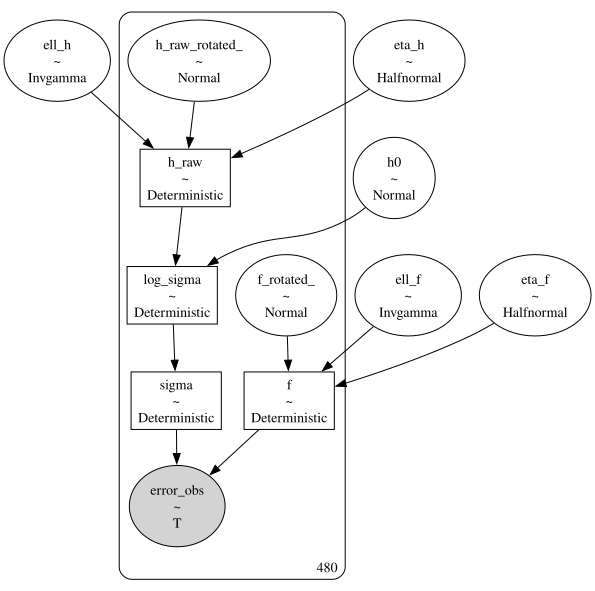

In [9]:
pm.model_to_graphviz(model)


## 7. Variational Inference Diagnostics

`ELBO loss` の推移と、変分近似からの posterior sample summary を確認します。`r_hat` や divergence はMCMC診断なので、この推論法では使用しません。


In [10]:
summary = az.summary(
    idata,
    var_names=["ell_f", "eta_f", "ell_h", "eta_h", "h0"],
    round_to=3,
)

display(summary)

elbo = np.asarray(meta["vi_elbo_history"])
print("Inference method:", meta["inference_method"])
print("VI steps:", meta["vi_steps"])
print("VI samples:", meta["vi_samples"])
print("VI learning rate:", meta["vi_learning_rate"])
print("Final ELBO loss:", float(elbo[-1]))


arviz - WARNING - Shape validation failed: input_shape: (1, 4000), minimum_shape: (chains=2, draws=4)


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
ell_f,1.018,0.169,0.717,1.341,0.003,0.002,4045.631,3881.357,NaN
eta_f,6.159,0.526,5.185,7.139,0.008,0.006,3813.241,3649.473,NaN
ell_h,0.561,0.065,0.438,0.681,0.001,0.001,4099.777,3670.470,NaN
eta_h,0.672,0.048,0.584,0.760,0.001,0.001,3866.308,3553.971,NaN
h0,2.474,0.043,2.399,2.557,0.001,0.000,3920.640,3584.179,NaN


Inference method: advi
VI steps: 100000
VI samples: 4000
VI learning rate: 0.0001
Final ELBO loss: 2016.5467578202522


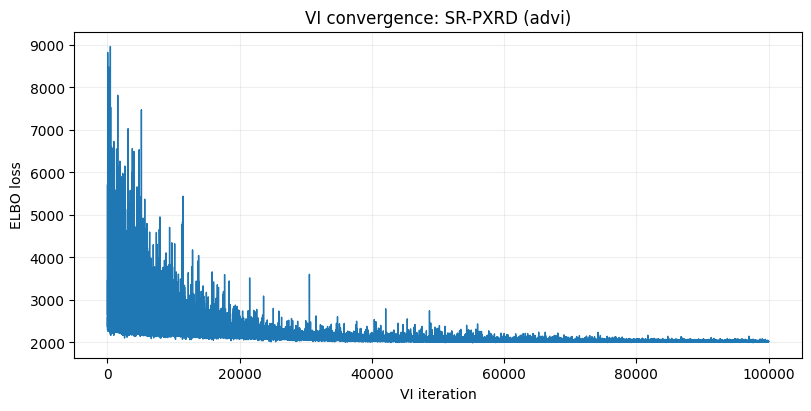

In [11]:
elbo = np.asarray(meta["vi_elbo_history"])

fig, ax = plt.subplots(figsize=(8, 4), constrained_layout=True)
ax.plot(elbo, linewidth=1)
ax.set_xlabel("VI iteration")
ax.set_ylabel("ELBO loss")
ax.set_title(f"VI convergence: {DEVICE_TO_USE} ({VI_METHOD})")
ax.grid(True, alpha=0.2)
plt.show()


## 8. Prediction Intervals

予測グリッド上で、潜在的な平均誤差、Student-t error scale、その scale から定まる条件付き標準偏差、および次回の signed relative error の予測区間を計算します。

$$
e_{\mathrm{new}}(x)=f(x)+\sigma(x)T,\qquad T\sim t_{\nu}(0,1)
$$

### 主な中間変数

| 変数 | 内容 |
|---|---|
| `x_grid_raw` | 結果を予測する WDXRF reference concentration のグリッド（wt.%）です。 |
| `x_grid_scaled`, `Xnew` | 学習時と同じ変換・標準化を適用した GP への入力です。`Xnew` は GP が要求する2次元形状です。 |
| `f_pred`, `f_arr` | 濃度 $x$ における潜在平均関数 $f(x)$ の事後予測標本です。signed relative error の系統的な平均傾向を表し、単位は percent です。 |
| `h_raw_pred`, `h_raw_arr` | 濃度に依存して変化する log-scale GP 成分 $h_{\mathrm{raw}}(x)$ の事後予測標本です。 |
| `h0_arr` | log-scale の全体的な基準値 $h_0$ の事後標本です。 |
| `log_sigma_arr` | $\log\sigma(x)=h_0+h_{\mathrm{raw}}(x)$ の事後予測標本です。 |
| `sigma_arr` | $\sigma(x)=\exp[\log\sigma(x)]$ の事後予測標本です。これは Student-t 分布の正の scale parameter で、単位は percent です。標準偏差そのものではありません。 |
| `e_new_arr` | 各事後標本について $f(x)+\sigma(x)T$ から生成した、次回観測される signed relative error の事後予測標本です。Student-t の観測変動と、$f(x)$ および $\sigma(x)$ の推定不確実性を含みます。 |
| `f_flat`, `sigma_flat`, `e_new_flat` | chain 軸と draw 軸を1本の sample 軸にまとめ、濃度ごとの分位点を計算できる形にした配列です。 |

Student-t 分布では、自由度 $\nu>2$ のときの条件付き標準偏差は

$$
\operatorname{SD}\!\left[e_{\mathrm{new}}(x)\mid f(x),\sigma(x),\nu\right]
=\sigma(x)\sqrt{\frac{\nu}{\nu-2}}
$$

です。したがって、このノートブックの $\nu=4$ では条件付き標準偏差は $\sqrt{2}\,\sigma(x)$ です。コードが保存する `sigma_*` 列はこの標準偏差ではなく、$\sigma(x)$ の要約です。

### 出力列

| 出力列 | 内容 |
|---|---|
| `mean_error_median` | 潜在平均誤差 $f(x)$ の事後中央値です。 |
| `mean_error_lower95`, `mean_error_upper95` | $f(x)$ の95%事後信用区間です。次回観測値の予測区間ではありません。 |
| `sigma_median` | Student-t error scale $\sigma(x)$ の事後中央値です。 |
| `sigma_lower95`, `sigma_upper95` | $\sigma(x)$ の95%事後信用区間です。 |
| `pred_error_median` | 次回 signed relative error、$e_{\mathrm{new}}(x)$ の事後予測中央値です。 |
| `pred_error_lower50`, `pred_error_upper50` | $e_{\mathrm{new}}(x)$ の中央50%予測区間（25–75%分位点）です。 |
| `pred_error_lower90`, `pred_error_upper90` | $e_{\mathrm{new}}(x)$ の中央90%予測区間（5–95%分位点）です。 |
| `pred_error_lower95`, `pred_error_upper95` | $e_{\mathrm{new}}(x)$ の中央95%予測区間（2.5–97.5%分位点）です。 |

`mean_error_*` と `sigma_*` は潜在パラメータの不確実性を示す事後要約であり、`pred_error_*` は次回観測値そのもののばらつきを示す予測要約です。

In [12]:
def predict_one_device_latent_heteroscedastic_gp(
    model,
    idata,
    meta,
    gp_objects,
    x_grid_raw,
    pred_suffix="v1",
    random_seed=123,
):
    """
    予測グリッド上で、平均誤差、標準偏差、次回errorの予測区間を計算する。

    Notes
    -----
    この関数は model に f_pred_{suffix}, h_raw_pred_{suffix} を追加する。
    同じモデルで何度も呼ぶ場合は、pred_suffix を変えてください。
    """

    rng = np.random.default_rng(random_seed)

    x_grid_raw = np.asarray(x_grid_raw, dtype=float)

    x_grid_scaled = transform_x_new(
        x_grid_raw,
        meta["transform_meta"],
    )

    Xnew = x_grid_scaled[:, None]

    gp_f = gp_objects["gp_f"]
    gp_h = gp_objects["gp_h"]

    f_name = f"f_pred_{pred_suffix}"
    h_name = f"h_raw_pred_{pred_suffix}"

    with model:
        # 予測点での平均GP
        f_pred = gp_f.conditional(
            f_name,
            Xnew=Xnew,
        )

        # 予測点でのlog_sigmaのraw GP成分
        h_raw_pred = gp_h.conditional(
            h_name,
            Xnew=Xnew,
        )

        ppc = pm.sample_posterior_predictive(
            idata,
            var_names=[f_name, h_name],
            random_seed=random_seed,
            return_inferencedata=True,
        )

    # shape: chain, draw, n_grid
    f_arr = ppc.posterior_predictive[f_name].values
    h_raw_arr = ppc.posterior_predictive[h_name].values

    # h0 はposteriorから取り出す
    h0_arr = idata.posterior["h0"].values  # chain, draw

    # log_sigma = h0 + h_raw
    log_sigma_arr = h0_arr[:, :, None] + h_raw_arr

    sigma_arr = np.exp(log_sigma_arr)

    # 次回errorを生成
    # e_new_arr = rng.normal(
    #     loc=f_arr,
    #     scale=sigma_arr,
    # )
    e_new_arr = (
        f_arr
        + sigma_arr
        * rng.standard_t(
            df=meta["student_t_nu"],
            size=f_arr.shape,
        )
    )

    # chain, draw をsample軸にまとめる
    n_chain, n_draw, n_grid = f_arr.shape

    f_flat = f_arr.reshape(n_chain * n_draw, n_grid)
    sigma_flat = sigma_arr.reshape(n_chain * n_draw, n_grid)
    e_new_flat = e_new_arr.reshape(n_chain * n_draw, n_grid)

    result = pd.DataFrame({
        "ref_wt": x_grid_raw,

        # 平均誤差関数 f(x)
        "mean_error_median": np.quantile(f_flat, 0.50, axis=0),
        "mean_error_lower95": np.quantile(f_flat, 0.025, axis=0),
        "mean_error_upper95": np.quantile(f_flat, 0.975, axis=0),

        # 標準偏差 sigma(x)
        "sigma_median": np.quantile(sigma_flat, 0.50, axis=0),
        "sigma_lower95": np.quantile(sigma_flat, 0.025, axis=0),
        "sigma_upper95": np.quantile(sigma_flat, 0.975, axis=0),

        # 次回errorの予測分布
        "pred_error_median": np.quantile(e_new_flat, 0.50, axis=0),
        "pred_error_lower50": np.quantile(e_new_flat, 0.25, axis=0),
        "pred_error_upper50": np.quantile(e_new_flat, 0.75, axis=0),
        "pred_error_lower90": np.quantile(e_new_flat, 0.05, axis=0),
        "pred_error_upper90": np.quantile(e_new_flat, 0.95, axis=0),
        "pred_error_lower95": np.quantile(e_new_flat, 0.025, axis=0),
        "pred_error_upper95": np.quantile(e_new_flat, 0.975, axis=0),
    })

    return result


In [13]:
def make_prediction_grid(df_device, n_grid=100):
    x_min = df_device["ref_wt"].min()
    x_max = df_device["ref_wt"].max()
    return np.logspace(np.log10(x_min), np.log10(x_max), n_grid)


x_grid = make_prediction_grid(df, N_GRID)

pred = predict_one_device_latent_heteroscedastic_gp(
    model=model,
    idata=idata,
    meta=meta,
    gp_objects=gp_objects,
    x_grid_raw=x_grid,
    pred_suffix=PRED_SUFFIX,
    random_seed=RANDOM_SEED,
)

pred.insert(0, "device", DEVICE_TO_USE)
display(pred.head())


Sampling: [f_pred_real_v1, h_raw_pred_real_v1]


Output()

,device,ref_wt,mean_error_median,mean_error_lower95,mean_error_upper95,sigma_median,sigma_lower95,sigma_upper95,pred_error_median,pred_error_lower50,pred_error_upper50,pred_error_lower90,pred_error_upper90,pred_error_lower95,pred_error_upper95
0,SR-PXRD,0.064000,-0.700955,-4.533903,3.331402,21.059174,11.209312,38.864148,-0.676537,-16.508760,15.036329,-49.155348,46.709668,-63.798371,65.073527
1,SR-PXRD,0.068736,-0.848214,-4.616495,2.998446,21.298148,11.689588,37.915725,-0.039227,-16.192186,14.804444,-49.136074,47.075375,-64.300245,62.119258
2,SR-PXRD,0.073822,-1.000147,-4.679384,2.711164,21.460566,12.125287,37.100208,-0.339611,-16.297315,15.955856,-47.941631,49.859123,-63.761189,64.412222
3,SR-PXRD,0.079284,-1.156968,-4.748117,2.488087,21.540310,12.583208,36.366718,-1.038900,-17.290994,14.741064,-50.154339,47.188614,-63.259872,65.437927
4,SR-PXRD,0.085151,-1.323011,-4.802455,2.254603,21.621029,12.967469,35.483029,-0.907095,-16.420031,14.163991,-49.462073,46.192335,-66.204818,60.220439


## 9. Plot Prediction Intervals

点は観測値、帯は次回観測値の prediction interval、破線は平均誤差曲線です。

Saved: /Volumes/SSD-PHPU3A/研究/0_DATA/6_EPMA_XRD検証/0_Data/3_Figure/Mineral_Mode_Relative_Error/one_device_prediction_interval_SR-PXRD_ADVI_tstudent.png


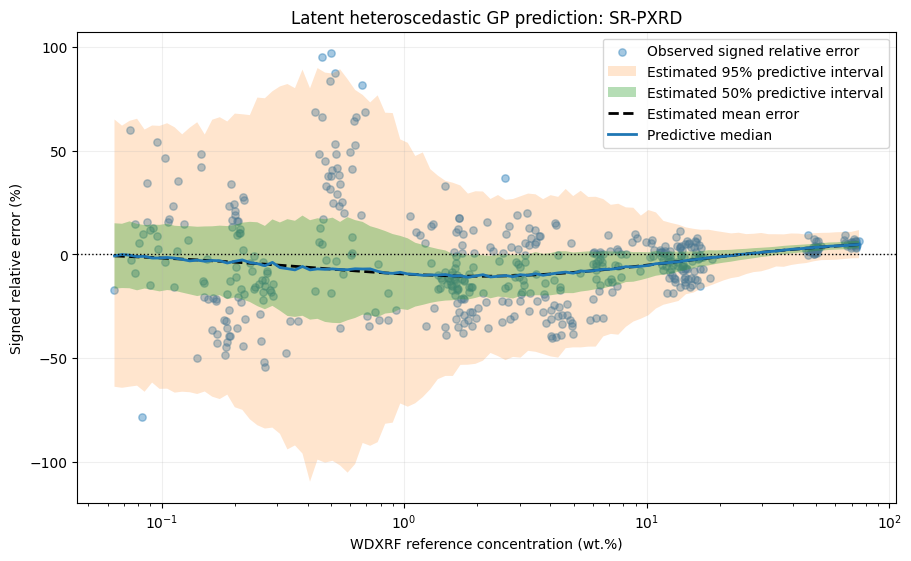

In [14]:
def plot_prediction(df, pred, save_path=None):
    fig, ax = plt.subplots(figsize=(9, 5.5), constrained_layout=True)

    ax.scatter(
        df["ref_wt"],
        df["error"],
        alpha=0.40,
        s=28,
        label="Observed signed relative error",
    )

    ax.fill_between(
        pred["ref_wt"],
        pred["pred_error_lower95"],
        pred["pred_error_upper95"],
        alpha=0.20,
        label="Estimated 95% predictive interval",
    )

    ax.fill_between(
        pred["ref_wt"],
        pred["pred_error_lower50"],
        pred["pred_error_upper50"],
        alpha=0.35,
        label="Estimated 50% predictive interval",
    )

    ax.plot(
        pred["ref_wt"],
        pred["mean_error_median"],
        linestyle="--",
        linewidth=2,
        color="black",
        label="Estimated mean error",
    )

    ax.plot(
        pred["ref_wt"],
        pred["pred_error_median"],
        linewidth=2,
        label="Predictive median",
    )

    ax.axhline(0, linestyle=":", linewidth=1, color="black")
    ax.set_xscale("log")
    ax.set_xlabel("WDXRF reference concentration (wt.%)")
    ax.set_ylabel("Signed relative error (%)")
    ax.set_title(f"Latent heteroscedastic GP prediction: {DEVICE_TO_USE}")
    ax.grid(True, which="major", alpha=0.2)
    ax.legend()

    if save_path is not None:
        save_path = Path(save_path)
        save_path.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_path, dpi=300, bbox_inches="tight")
        print(f"Saved: {save_path}")

    plt.show()


plot_prediction(
    df,
    pred,
    save_path=FIGURE_DIR / f"one_device_prediction_interval_{safe_name(DEVICE_TO_USE)}_{RESULT_SUFFIX}.png",
)


## 10. Plot Estimated Heteroscedasticity

濃度に依存する signed relative error の Student-t error scale $\sigma(x)$ を確認します。

$$
e(x) \mid f(x),\sigma(x),\nu
\sim \mathrm{StudentT}\!\left(\nu,\mu=f(x),\mathrm{scale}=\sigma(x)\right)
$$

$\sigma(x)$ は、signed relative error が平均関数 $f(x)$ の周囲にどの程度広がるかを表す正の尺度パラメータです。値が大きい濃度域ほど誤差分布が広く、小さい濃度域ほど狭くなります。応答変数が percent 表示のため、$\sigma(x)$ の単位も percent です。

Student-t 分布では $\sigma$ は標準偏差そのものではありません。$\nu>2$ のとき、条件付き標準偏差は

$$
\operatorname{SD}\!\left[e(x)\mid f(x),\sigma(x),\nu\right]
=\sigma(x)\sqrt{\frac{\nu}{\nu-2}}
$$

です。このノートブックの $\nu=4$ では、条件付き標準偏差は $\sqrt{2}\,\sigma(x)$ です。実線は $\sigma(x)$ の事後中央値、帯はその 95% credible interval を示します。

Saved: /Volumes/SSD-PHPU3A/研究/0_DATA/6_EPMA_XRD検証/0_Data/3_Figure/Mineral_Mode_Relative_Error/one_device_sigma_SR-PXRD_ADVI_tstudent.png


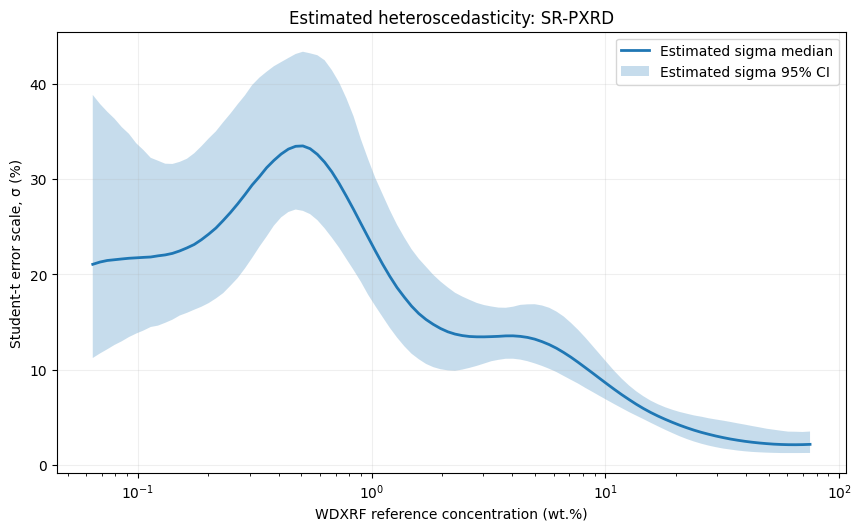

In [15]:
def plot_sigma(pred, save_path=None):
    fig, ax = plt.subplots(figsize=(8.5, 5.2), constrained_layout=True)

    ax.plot(
        pred["ref_wt"],
        pred["sigma_median"],
        linewidth=2,
        label="Estimated sigma median",
    )

    ax.fill_between(
        pred["ref_wt"],
        pred["sigma_lower95"],
        pred["sigma_upper95"],
        alpha=0.25,
        label="Estimated sigma 95% CI",
    )

    ax.set_xscale("log")
    ax.set_xlabel("WDXRF reference concentration (wt.%)")
    ax.set_ylabel("Student-t error scale, σ (%)")
    ax.set_title(f"Estimated heteroscedasticity: {DEVICE_TO_USE}")
    ax.grid(True, which="major", alpha=0.2)
    ax.legend()

    if save_path is not None:
        save_path = Path(save_path)
        save_path.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_path, dpi=300, bbox_inches="tight")
        print(f"Saved: {save_path}")

    plt.show()


plot_sigma(
    pred,
    save_path=FIGURE_DIR / f"one_device_sigma_{safe_name(DEVICE_TO_USE)}_{RESULT_SUFFIX}.png",
)


## 11. Save Results

予測値、MCMC summary、モデル入力データを保存します。

In [16]:
pred_out = pred.copy()

device_safe = f"{safe_name(DEVICE_TO_USE)}_{RESULT_SUFFIX}"
pred_path = OUTPUT_DIR / f"one_device_latent_hgp_real_data_predictions_{device_safe}.csv"
summary_path = OUTPUT_DIR / f"one_device_latent_hgp_real_data_mcmc_summary_{device_safe}.csv"
model_data_path = OUTPUT_DIR / f"one_device_latent_hgp_real_data_model_data_{device_safe}.csv"

pred_out.to_csv(pred_path, index=False)
summary.to_csv(summary_path)
df.to_csv(model_data_path, index=False)

print("Saved predictions:", pred_path)
print("Saved MCMC summary:", summary_path)
print("Saved model data:", model_data_path)

display(pred_out.head())


Saved predictions: /Volumes/SSD-PHPU3A/研究/0_DATA/6_EPMA_XRD検証/0_Data/3_Figure/Mineral_Mode_Relative_Error/one_device_latent_hgp_real_data_predictions_SR-PXRD_ADVI_tstudent.csv
Saved MCMC summary: /Volumes/SSD-PHPU3A/研究/0_DATA/6_EPMA_XRD検証/0_Data/3_Figure/Mineral_Mode_Relative_Error/one_device_latent_hgp_real_data_mcmc_summary_SR-PXRD_ADVI_tstudent.csv
Saved model data: /Volumes/SSD-PHPU3A/研究/0_DATA/6_EPMA_XRD検証/0_Data/3_Figure/Mineral_Mode_Relative_Error/one_device_latent_hgp_real_data_model_data_SR-PXRD_ADVI_tstudent.csv


,device,ref_wt,mean_error_median,mean_error_lower95,mean_error_upper95,sigma_median,sigma_lower95,sigma_upper95,pred_error_median,pred_error_lower50,pred_error_upper50,pred_error_lower90,pred_error_upper90,pred_error_lower95,pred_error_upper95
0,SR-PXRD,0.064000,-0.700955,-4.533903,3.331402,21.059174,11.209312,38.864148,-0.676537,-16.508760,15.036329,-49.155348,46.709668,-63.798371,65.073527
1,SR-PXRD,0.068736,-0.848214,-4.616495,2.998446,21.298148,11.689588,37.915725,-0.039227,-16.192186,14.804444,-49.136074,47.075375,-64.300245,62.119258
2,SR-PXRD,0.073822,-1.000147,-4.679384,2.711164,21.460566,12.125287,37.100208,-0.339611,-16.297315,15.955856,-47.941631,49.859123,-63.761189,64.412222
3,SR-PXRD,0.079284,-1.156968,-4.748117,2.488087,21.540310,12.583208,36.366718,-1.038900,-17.290994,14.741064,-50.154339,47.188614,-63.259872,65.437927
4,SR-PXRD,0.085151,-1.323011,-4.802455,2.254603,21.621029,12.967469,35.483029,-0.907095,-16.420031,14.163991,-49.462073,46.192335,-66.204818,60.220439


## 12. Computation Notes

このモデルは観測点ごとに平均GPとログ標準偏差GPの潜在変数を持つため、データ点数が多いほど重くなります。最初は `DRAWS=50`, `TUNE=50` などで smoke test してから、既定値に戻すと挙動を確認しやすいです。

In [17]:
end = time.perf_counter()
print("Elapsed minutes: {:.2f}".format((end - start) / 60))


Elapsed minutes: 14.20
